# Handwritten digit classification with TensorFlow

An **AI-assisted learning project** using TensorFlow/Keras and MNIST. This notebook
demonstrates preprocessing, validation-based model selection, held-out evaluation,
and error analysis. Its saved outputs come from an actual execution of these cells.

**Learning reference:** [TensorFlow's beginner quickstart](https://www.tensorflow.org/tutorials/quickstart/beginner).
This implementation adds an explicit validation split, a two-model comparison, a
majority-class baseline, a confusion matrix, saved metrics, and prediction examples.

Run in **Google Colab** using the link in the project README, or install
`requirements.txt` in a Python 3.12 environment. Colab can use its preinstalled
TensorFlow version; the notebook records the versions actually used. The committed
run uses the pinned local environment.

## 1. Environment and repeatability

Set seeds before training, request deterministic operations, and limit worker
threads so this small experiment also runs on modest CPU machines. Hardware and
package versions can still affect numerical results. No GPU is required.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "2")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")

from datetime import datetime, timezone
import json
from pathlib import Path
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

SEED = 42
EPOCHS = 5
BATCH_SIZE = 128
TRAIN_SIZE = 12_000
VALIDATION_SIZE = 3_000
OUTPUT = Path("results")
OUTPUT.mkdir(exist_ok=True)

tf.keras.utils.set_random_seed(SEED)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()

environment = {
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "keras": tf.keras.__version__,
    "numpy": np.__version__,
    "device": "GPU" if tf.config.list_physical_devices("GPU") else "CPU",
}
print(json.dumps(environment, indent=2))

{
  "python": "3.12.14",
  "tensorflow": "2.20.0",
  "keras": "3.15.1",
  "numpy": "2.5.5",
  "device": "CPU"
}


## 2. Load and split the data

MNIST contains 28×28 grayscale digit images. Use **12,000 training examples** and
**3,000 validation examples**, sampled without replacement from the original
60,000-example training partition. The remaining 45,000 examples are unused to
keep this learning run quick. Preserve the original **10,000-example test set**.

Convert pixel values from 0–255 to float32 values in 0–1. Model selection will use
the validation set; the test set is reserved for the selected model's final report.

In [2]:
(original_images, original_labels), (test_images, test_labels) = tf.keras.datasets.mnist.load_data()
indices = np.random.default_rng(SEED).permutation(len(original_images))
train_indices = indices[:TRAIN_SIZE]
validation_indices = indices[TRAIN_SIZE:TRAIN_SIZE + VALIDATION_SIZE]
assert not np.intersect1d(train_indices, validation_indices).size

x_train = original_images[train_indices].astype("float32") / 255.0
y_train = original_labels[train_indices]
x_validation = original_images[validation_indices].astype("float32") / 255.0
y_validation = original_labels[validation_indices]
x_test = test_images.astype("float32") / 255.0
y_test = test_labels

assert x_train.shape == (TRAIN_SIZE, 28, 28)
assert x_validation.shape == (VALIDATION_SIZE, 28, 28)
assert x_test.shape == (10_000, 28, 28)
assert x_train.min() >= 0 and x_train.max() <= 1
assert set(np.unique(y_train)) == set(range(10))
split = {"train": len(y_train), "validation": len(y_validation), "test": len(y_test), "unused_original_train": 45_000}
print("Partition sizes:", split)
print("Training label counts:", np.bincount(y_train, minlength=10).tolist())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Partition sizes: {'train': 12000, 'validation': 3000, 'test': 10000, 'unused_original_train': 45000}
Training label counts: [1211, 1369, 1189, 1267, 1168, 1063, 1179, 1222, 1152, 1180]


## 3. Prepare input pipelines and define the model

`tf.data` supplies batches, shuffles training examples, and prefetches one batch.
Validation and test examples retain their order. Flatten each image, learn a
hidden representation, then produce ten **logits** (unnormalised class scores).
`SparseCategoricalCrossentropy(from_logits=True)` accepts integer digit labels.

In [3]:
def make_dataset(images, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        dataset = dataset.shuffle(len(labels), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return dataset.batch(BATCH_SIZE).with_options(options).prefetch(1)

def build_model(hidden_units, dropout):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(hidden_units, activation="relu"),
        tf.keras.layers.Dropout(dropout),
        tf.keras.layers.Dense(10),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    return model

validation_dataset = make_dataset(x_validation, y_validation)
print("Input shape:", x_train.shape[1:], "| Batch size:", BATCH_SIZE)

Input shape: (28, 28) | Batch size: 128


## 4. Compare two candidate models

Train a 64-unit baseline without dropout and a 128-unit model with 0.2 dropout.
Both use the same data, optimiser, batch size, epoch count, and seed. This changes
**both width and dropout**, so it does not isolate the causal effect of dropout.
Select using final validation accuracy, breaking a tie with lower validation loss.

In [4]:
configurations = [
    {"name": "dense_64", "hidden_units": 64, "dropout": 0.0},
    {"name": "dense_128_dropout", "hidden_units": 128, "dropout": 0.2},
]
trained_models = {}
histories = {}
experiments = []
for configuration in configurations:
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(configuration["hidden_units"], configuration["dropout"])
    started = time.perf_counter()
    history = model.fit(
        make_dataset(x_train, y_train, training=True),
        validation_data=validation_dataset, epochs=EPOCHS, verbose=0,
    )
    validation = model.evaluate(validation_dataset, verbose=0, return_dict=True)
    experiment = {
        **configuration,
        "epochs": EPOCHS,
        "validation_accuracy": float(validation["accuracy"]),
        "validation_loss": float(validation["loss"]),
        "training_seconds": round(time.perf_counter() - started, 3),
    }
    trained_models[configuration["name"]] = model
    histories[configuration["name"]] = history.history
    experiments.append(experiment)
    print(json.dumps(experiment, indent=2))

selected = max(experiments, key=lambda item: (item["validation_accuracy"], -item["validation_loss"]))
selected_model = trained_models[selected["name"]]
print("Selected on validation data:", selected["name"])

{
  "name": "dense_64",
  "hidden_units": 64,
  "dropout": 0.0,
  "epochs": 5,
  "validation_accuracy": 0.9313333630561829,
  "validation_loss": 0.24377965927124023,
  "training_seconds": 1.59
}
{
  "name": "dense_128_dropout",
  "hidden_units": 128,
  "dropout": 0.2,
  "epochs": 5,
  "validation_accuracy": 0.9440000057220459,
  "validation_loss": 0.20496049523353577,
  "training_seconds": 1.565
}
Selected on validation data: dense_128_dropout


/workspace/scratch/17cb8865c249/.verification-env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


## 5. Evaluate once on held-out test data

Only the selected model receives a final test accuracy. A second inference pass
produces predictions for the confusion matrix and examples; test outcomes are
not used to select or retrain the model. Compare against a majority-class
baseline whose predicted digit is chosen from training labels.

In [5]:
test_dataset = make_dataset(x_test, y_test)
test_metrics = selected_model.evaluate(test_dataset, verbose=0, return_dict=True)
logits = selected_model.predict(test_dataset, verbose=0)
probabilities = tf.nn.softmax(logits).numpy()
predictions = probabilities.argmax(axis=1)
confusion = tf.math.confusion_matrix(y_test, predictions, num_classes=10).numpy()
majority_digit = int(np.bincount(y_train, minlength=10).argmax())
majority_accuracy = float(np.mean(y_test == majority_digit))
assert confusion.sum() == len(y_test)
assert abs(np.trace(confusion) / len(y_test) - test_metrics["accuracy"]) < 1e-6

metrics = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "environment": environment,
    "split": split,
    "batch_size": BATCH_SIZE,
    "experiments": experiments,
    "selection_rule": "highest final validation accuracy; lower validation loss breaks ties",
    "selected_model": selected["name"],
    "test_accuracy": float(test_metrics["accuracy"]),
    "test_loss": float(test_metrics["loss"]),
    "majority_training_digit": majority_digit,
    "majority_baseline_test_accuracy": majority_accuracy,
    "confusion_matrix": confusion.tolist(),
}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
selected_model.save(OUTPUT / "mnist-classifier.keras")  # Local output; excluded from Git.
print(f"Held-out test accuracy: {test_metrics['accuracy']:.4%}")
print(f"Majority-class baseline: {majority_accuracy:.4%} (always predicts {majority_digit})")
print("Saved results/metrics.json and a local .keras model.")

Held-out test accuracy: 94.1400%
Majority-class baseline: 11.3500% (always predicts 1)
Saved results/metrics.json and a local .keras model.


## 6. Inspect the training curves and errors

The first figure compares learning curves. In the confusion matrix, rows are
true labels and columns are predicted labels. The final grid shows the first
twelve incorrect predictions in test-set order, rather than cherry-picked cases.
Softmax scores express model confidence but have not been calibrated.

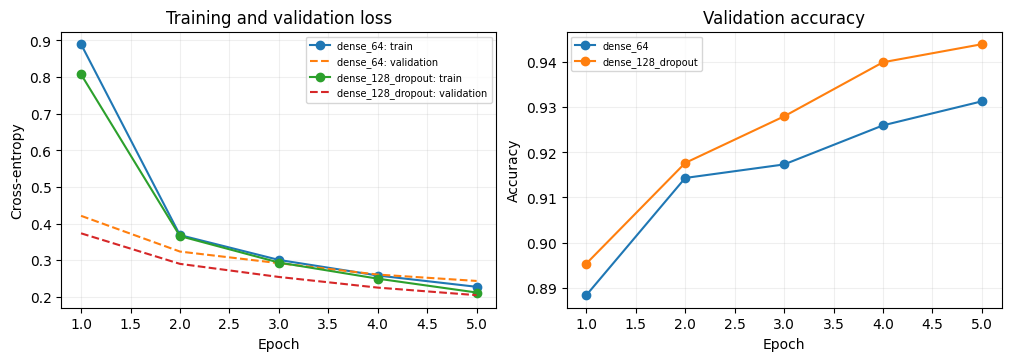

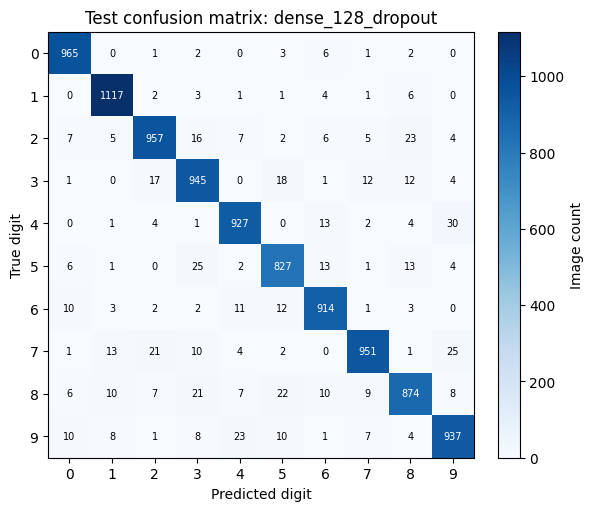

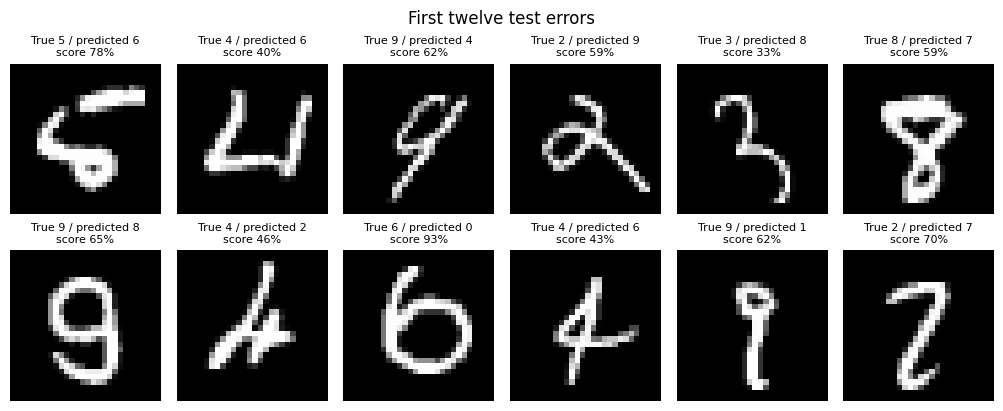

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for name, history in histories.items():
    epochs = range(1, EPOCHS + 1)
    axes[0].plot(epochs, history["loss"], marker="o", label=f"{name}: train")
    axes[0].plot(epochs, history["val_loss"], linestyle="--", label=f"{name}: validation")
    axes[1].plot(epochs, history["val_accuracy"], marker="o", label=name)
axes[0].set(title="Training and validation loss", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
for axis in axes:
    axis.legend(fontsize=7)
    axis.grid(alpha=0.2)
fig.savefig(OUTPUT / "training.svg", metadata={"Date": None})
plt.show()

fig, axis = plt.subplots(figsize=(6, 5), layout="constrained")
image = axis.imshow(confusion, cmap="Blues")
axis.set(title=f"Test confusion matrix: {selected['name']}", xlabel="Predicted digit", ylabel="True digit", xticks=range(10), yticks=range(10))
for row in range(10):
    for column in range(10):
        axis.text(column, row, str(confusion[row, column]), ha="center", va="center", fontsize=7,
                  color="white" if confusion[row, column] > confusion.max() / 2 else "black")
fig.colorbar(image, ax=axis, label="Image count")
fig.savefig(OUTPUT / "confusion-matrix.svg", metadata={"Date": None})
plt.show()

incorrect = np.flatnonzero(predictions != y_test)[:12]
fig, axes = plt.subplots(2, 6, figsize=(10, 4), layout="constrained")
for axis in axes.flat:
    axis.axis("off")
for axis, index in zip(axes.flat, incorrect):
    axis.imshow(x_test[index], cmap="gray")
    axis.set_title(f"True {y_test[index]} / predicted {predictions[index]}\nscore {probabilities[index].max():.0%}", fontsize=8)
fig.suptitle("First twelve test errors")
fig.savefig(OUTPUT / "prediction-errors.svg", metadata={"Date": None})
plt.show()

## 7. Interpretation and next experiments

- Report the measured test accuracy from the output above; do not substitute a
  tutorial's result or promise the same result on a new run.
- The validation comparison is small and uses a single split and seed. Repeat
  with several seeds before drawing a strong conclusion about either architecture.
- MNIST is a benchmark dataset. Performance on it does not establish performance
  on photographs or handwriting collected from a different source.
- A useful next change is to hold the hidden-layer width fixed and vary only
  dropout. Another is to train on the full training partition while preserving a
  validation split and leaving the test set untouched until the end.

**Review exercise:** explain why normalisation, a validation set, `from_logits=True`,
and an untouched test set matter. Then change one hyperparameter, rerun, and record
your own observation before presenting this as a completed personal learning exercise.